# 5.1 Случайная выборка

# 5.1 随机采样

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4), "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#D55E00", "#009E73"]),
    "figure.dpi": 110,
})

Matplotlib is building the font cache; this may take a moment.


## Генератор NumPy
Один генератор выдаёт последовательность значений. Верхняя граница `integers` не включается.

## NumPy 随机数生成器
同一个生成器连续产生数值。`integers` 不包含上限。

In [2]:
rng = np.random.default_rng(42)
u = rng.uniform(0, 1, 1000)
z = rng.normal(0, 1, 1000)
i = rng.integers(0, 10, 1000)
print("u:", u[:5])
print("z:", z[:5])
print("i:", i[:10])

u: [0.77395605 0.43887844 0.85859792 0.69736803 0.09417735]
z: [-0.74219209  0.92435776  0.03461187 -0.28279575 -0.10618193]
i: [4 1 2 4 6 4 5 5 2 2]


## Воспроизводимость
При одинаковом генераторе, seed и порядке вызовов результаты повторяются. Для следующего опыта продолжаем использовать генератор, не сбрасывая его seed.

## 可重复性
生成器、seed 和调用顺序相同时，结果可重复。重复试验时继续使用生成器，不要在每次试验前重置 seed。

In [3]:
rng_a = np.random.default_rng(42)
rng_b = np.random.default_rng(42)
first = rng_a.random(5)
repeated = rng_b.random(5)
next_values = rng_a.random(5)
print("Первый вызов / 第一次调用:", first)
print("Повтор / 重现:", repeated)
print("Следующий вызов / 下一次调用:", next_values)
print("Совпадают / 相同:", np.array_equal(first, repeated))

Первый вызов / 第一次调用: [0.77395605 0.43887844 0.85859792 0.69736803 0.09417735]
Повтор / 重现: [0.77395605 0.43887844 0.85859792 0.69736803 0.09417735]
Следующий вызов / 下一次调用: [0.97562235 0.7611397  0.78606431 0.12811363 0.45038594]
Совпадают / 相同: True


## Гистограммы и плотности
`density=True` нормирует площадь гистограммы к единице. `normal(0, 1, ...)` задаёт среднее 0 и стандартное отклонение 1.

## 直方图与概率密度
`density=True` 使直方图总面积为 1。`normal(0, 1, ...)` 的均值为 0、标准差为 1。

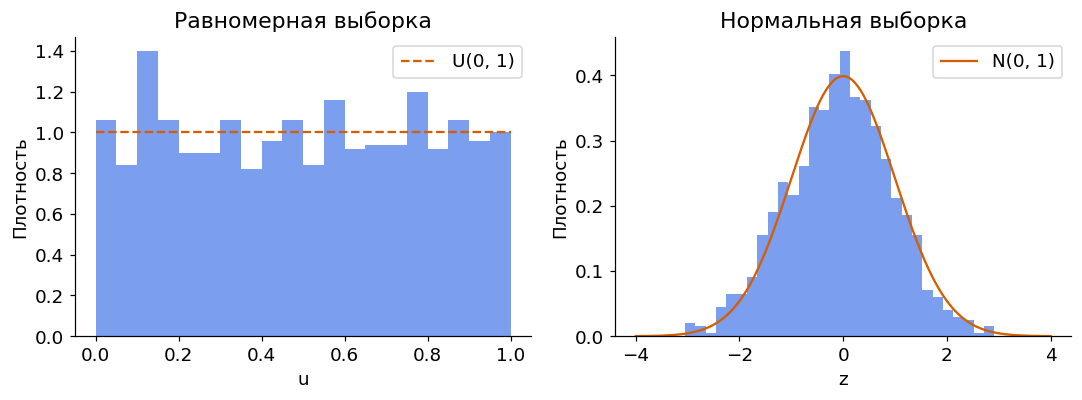

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(u, bins=20, range=(0, 1), density=True, alpha=0.65)
axes[0].plot([0, 1], [1, 1], "--", color="#D55E00", label="U(0, 1)")
axes[0].set(xlabel="u", ylabel="Плотность", title="Равномерная выборка")
grid = np.linspace(-4, 4, 300)
axes[1].hist(z, bins=30, density=True, alpha=0.65)
axes[1].plot(grid, np.exp(-grid**2 / 2) / np.sqrt(2 * np.pi),
             color="#D55E00", label="N(0, 1)")
axes[1].set(xlabel="z", ylabel="Плотность", title="Нормальная выборка")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

## Среднее, разброс и ошибка среднего
Стандартное отклонение описывает разброс отдельных значений. Стандартная ошибка среднего (SE) оценивает разброс средних по независимым выборкам. Здесь $SE=s/\sqrt{N}$, `ddof=1` задаёт выборочную дисперсию с делителем $N-1$.

## 均值、离散程度与均值误差
标准差描述单个数值的离散程度；均值标准误（SE）估计独立样本均值的波动。这里 $SE=s/\sqrt{N}$，`ddof=1` 使用分母 $N-1$ 计算样本方差。

In [5]:
for name, sample in [("U(0, 1)", u), ("N(0, 1)", z)]:
    mean = sample.mean()
    std = sample.std(ddof=1)
    se = std / np.sqrt(sample.size)
    print(f"{name}: mean={mean:.5f}, std={std:.5f}, SE={se:.5f}")

U(0, 1): mean=0.49718, std=0.29159, SE=0.00922
N(0, 1): mean=-0.07788, std=1.01447, SE=0.03208


## Накопленное среднее
Добавляем новые значения к одной выборке. Полоса $0.5\pm2/\sqrt{12N}$ показывает примерно две теоретические стандартные ошибки для каждого $N$, а не гарантированные границы всей траектории.

## 累积均值
在同一样本中不断加入新数值。阴影 $0.5\pm2/\sqrt{12N}$ 表示各个 $N$ 对应的约两个理论标准误，并不保证整条曲线都落在阴影内。

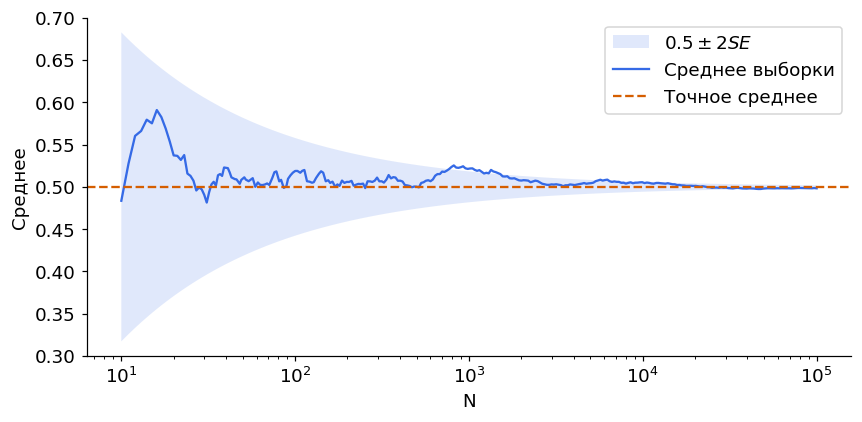

N=100000, mean=0.498254


In [6]:
rng_mean = np.random.default_rng(2026)
sample = rng_mean.uniform(0, 1, 100_000)
n = np.arange(1, sample.size + 1)
running_mean = np.cumsum(sample) / n
selected = np.unique(np.geomspace(10, sample.size, 300).astype(int))
se_theory = 1 / np.sqrt(12 * selected)
fig, ax = plt.subplots()
ax.fill_between(selected, 0.5 - 2 * se_theory, 0.5 + 2 * se_theory,
                alpha=0.15, label=r"$0.5 \pm 2SE$")
ax.semilogx(selected, running_mean[selected - 1], label="Среднее выборки")
ax.axhline(0.5, color="#D55E00", linestyle="--", label="Точное среднее")
ax.set(xlabel="N", ylabel="Среднее", ylim=(0.3, 0.7))
ax.legend()
fig.tight_layout()
plt.show()
print(f"N={sample.size}, mean={running_mean[-1]:.6f}")

## Попробуйте
Измените seed. Затем увеличьте число значений в гистограммах с 1000 до 10 000. Сравните форму гистограммы и SE.

## 练习
修改 seed，再把直方图样本量从 1000 增至 10 000。比较直方图形状和 SE。